In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
from scipy.optimize import linear_sum_assignment

In [8]:
iris = pd.read_csv(
    r"C:\Users\pruth\Downloads\archive\Iris.csv"
)

print(iris.head())
print("Dataset shape:", iris.shape)
print("Columns:", iris.columns.tolist())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Dataset shape: (150, 6)
Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


In [9]:
# Remove unnecessary ID column if present
iris = iris.drop(columns=["Id"], errors="ignore")

# Separate features and true labels
X = iris.drop(columns=["Species"])
y = iris["Species"]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features scaled successfully!")
print("Number of samples:", len(X))

Features scaled successfully!
Number of samples: 150


In [15]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

iris["Predicted_Cluster"] = clusters

print(iris.head(10))

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0            5.1           3.5            1.4           0.2  Iris-setosa   
1            4.9           3.0            1.4           0.2  Iris-setosa   
2            4.7           3.2            1.3           0.2  Iris-setosa   
3            4.6           3.1            1.5           0.2  Iris-setosa   
4            5.0           3.6            1.4           0.2  Iris-setosa   
5            5.4           3.9            1.7           0.4  Iris-setosa   
6            4.6           3.4            1.4           0.3  Iris-setosa   
7            5.0           3.4            1.5           0.2  Iris-setosa   
8            4.4           2.9            1.4           0.2  Iris-setosa   
9            4.9           3.1            1.5           0.1  Iris-setosa   

   Predicted_Cluster  
0                  1  
1                  1  
2                  1  
3                  1  
4                  1  
5                  1  
6 

C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


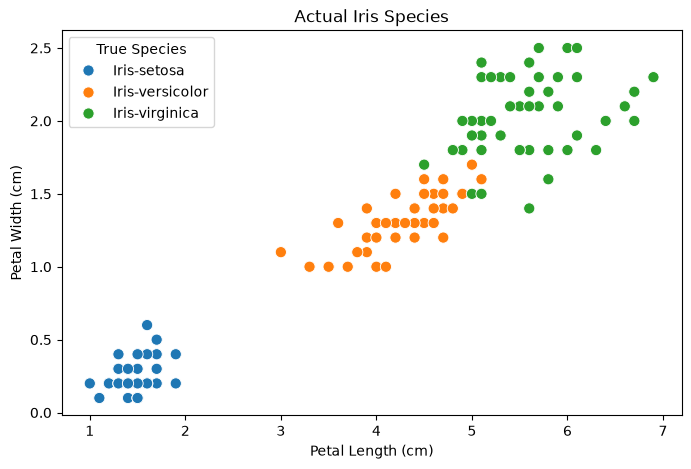

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X.iloc[:, 2],
    y=X.iloc[:, 3],
    hue=y,
    s=65
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Actual Iris Species")
plt.legend(title="True Species")
plt.show()

In [12]:
comparison = pd.crosstab(
    y,
    clusters,
    rownames=["True Species"],
    colnames=["Predicted Cluster"]
)

print(comparison)

Predicted Cluster   0   1   2
True Species                 
Iris-setosa         0  50   0
Iris-versicolor    39   0  11
Iris-virginica     14   0  36


Clustering Agreement: 83.33 %


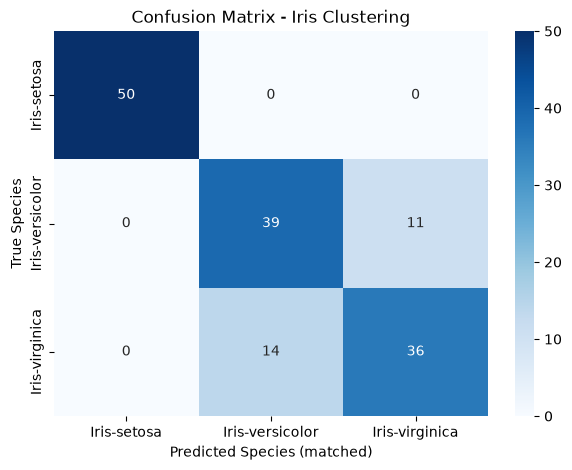

In [13]:
# Convert true species names into numeric labels
species_names = sorted(y.unique())
y_true = pd.Categorical(
    y, categories=species_names
).codes

# Create original confusion matrix
cm = confusion_matrix(y_true, clusters)

# Find the best mapping between clusters and species
rows, cols = linear_sum_assignment(-cm)

cluster_to_species = {
    cluster: species for species, cluster in zip(rows, cols)
}

y_pred = np.array([
    cluster_to_species[c] for c in clusters
])

# Calculate agreement
accuracy = accuracy_score(y_true, y_pred)

print("Clustering Agreement:", round(accuracy * 100, 2), "%")

# Plot matched confusion matrix
cm_matched = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_matched,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=species_names,
    yticklabels=species_names
)

plt.xlabel("Predicted Species (matched)")
plt.ylabel("True Species")
plt.title("Confusion Matrix - Iris Clustering")
plt.show()

In [14]:
print("PROJECT RESULT")
print("-----------------------------")
print("Algorithm: K-Means Clustering")
print("Number of clusters: 3")
print("Total flowers:", len(iris))
print("Features used:", X.shape[1])
print("Clustering agreement:", round(accuracy * 100, 2), "%")

iris.head(10)

PROJECT RESULT
-----------------------------
Algorithm: K-Means Clustering
Number of clusters: 3
Total flowers: 150
Features used: 4
Clustering agreement: 83.33 %


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Predicted_Cluster
0,5.1,3.5,1.4,0.2,Iris-setosa,1
1,4.9,3.0,1.4,0.2,Iris-setosa,1
2,4.7,3.2,1.3,0.2,Iris-setosa,1
3,4.6,3.1,1.5,0.2,Iris-setosa,1
4,5.0,3.6,1.4,0.2,Iris-setosa,1
5,5.4,3.9,1.7,0.4,Iris-setosa,1
6,4.6,3.4,1.4,0.3,Iris-setosa,1
7,5.0,3.4,1.5,0.2,Iris-setosa,1
8,4.4,2.9,1.4,0.2,Iris-setosa,1
9,4.9,3.1,1.5,0.1,Iris-setosa,1
